# 05 · Modelos de ensemble

En este notebook entrenamos los tres ensembles que pide el enunciado:

- **Random Forest** (bagging): muchos árboles profundos entrenados con muestras distintas y votando.
- **Gradient Boosting** de sklearn (boosting): árboles pequeños que se entrenan uno detrás de otro corrigiendo los errores del anterior.
- **XGBoost** (boosting): la misma idea, con regularización y más rápido.

Usamos el mismo esquema que en los modelos base (notebook 03): validación cruzada de 5 particiones sobre el train en las 12 configuraciones de preprocesamiento, eligiendo por F1 macro. Así podemos compararlos directamente con la logística y el árbol del notebook 04.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import f1_score
from xgboost import XGBClassifier

sys.path.append(str(Path.cwd().parent))
from src.config import SEED, RESULTS_DIR
from src.preprocesamiento import pesos_balanceados
from src.validacion import (cargar_datos, dividir_train_test, METRICAS, ajustar_modelo, particiones_cv,
                            mejor_configuracion, pipeline_desde_fila, entrenar_final, comparar_modelos,
                            guardar_tabla)

COLUMNAS = ["imputacion", "escalado", "balanceo", "mejores_parametros", "f1_macro_media", "f1_macro_std",
            "recall_alto_media", "bal_acc_media", "accuracy_media", "sobreajuste", "segundos"]

## 1. Datos

Misma partición que en los notebooks anteriores.

In [2]:
X, y = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(X, y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1803, 27)  Test: (451, 27)


In [3]:
def mapa_configuraciones(tabla, metrica, titulo, ax):
    # una fila por imputación/escalado y una columna por balanceo
    t = tabla.assign(prep=tabla.imputacion + " / " + tabla.escalado)
    t = t.pivot(index="prep", columns="balanceo", values=metrica)[["ninguno", "class_weight", "smotenc"]]
    sns.heatmap(t, annot=True, fmt=".3f", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(titulo)
    ax.set_xlabel("balanceo")
    ax.set_ylabel("imputación / escalado")


def figura_configuraciones(tabla, nombre, archivo):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    mapa_configuraciones(tabla, "f1_macro_media", f"{nombre}: F1 macro (CV)", axes[0])
    mapa_configuraciones(tabla, "recall_alto_media", f"{nombre}: recall riesgo alto (CV)", axes[1])
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / archivo, dpi=150)
    plt.show()


def importancias(pipe):
    nombres = pipe[:-1].transform(X_train.head()).columns
    return pd.Series(pipe[-1].feature_importances_, index=nombres).sort_values(ascending=False)

## 2. Random Forest

Hiperparámetros que ajustamos:

- `max_depth`: sin límite, 6 o 10.
- `min_samples_leaf`: 1, 5 o 20 pacientes por hoja.
- `max_features`: cuántas variables mira cada división (`sqrt` o el 30 %). Cuantas menos, más distintos son los árboles entre sí.

Dejamos fijo `n_estimators=300`: con más árboles el resultado casi no cambia y solo tarda más. Son 18 combinaciones por configuración, así que usamos `GridSearchCV`. Random Forest sí tiene `class_weight`.

In [4]:
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)
tabla_rf, busquedas_rf = ajustar_modelo(
    "random_forest", rf,
    {"max_depth": [None, 6, 10], "min_samples_leaf": [1, 5, 20], "max_features": ["sqrt", 0.3]},
    X_train, y_train)
guardar_tabla(tabla_rf, "ensembles_random_forest")
tabla_rf[COLUMNAS].round(3)

random_forest | mediana-estandar-ninguno         F1 macro 0.597 (±0.038)  recall alto 0.559  [11 s]


random_forest | mediana-estandar-class_weight    F1 macro 0.636 (±0.032)  recall alto 0.709  [7 s]


random_forest | mediana-estandar-smotenc         F1 macro 0.624 (±0.026)  recall alto 0.698  [12 s]


random_forest | mediana-yeojohnson-ninguno       F1 macro 0.598 (±0.039)  recall alto 0.562  [8 s]


random_forest | mediana-yeojohnson-class_weight  F1 macro 0.634 (±0.031)  recall alto 0.709  [7 s]


random_forest | mediana-yeojohnson-smotenc       F1 macro 0.626 (±0.024)  recall alto 0.684  [12 s]


... (3 outputs left out)

random_forest | knn-yeojohnson-ninguno           F1 macro 0.599 (±0.036)  recall alto 0.560  [9 s]


random_forest | knn-yeojohnson-class_weight      F1 macro 0.633 (±0.025)  recall alto 0.698  [8 s]


random_forest | knn-yeojohnson-smotenc           F1 macro 0.621 (±0.027)  recall alto 0.690  [13 s]


,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,f1_macro_std,recall_alto_media,bal_acc_media,accuracy_media,sobreajuste,segundos
0,mediana,estandar,class_weight,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.636,0.032,0.709,0.643,0.671,0.341,7.3
1,mediana,yeojohnson,class_weight,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.634,0.031,0.709,0.642,0.669,0.343,7.5
2,knn,estandar,class_weight,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.633,0.021,0.706,0.640,0.671,0.352,8.0
3,knn,yeojohnson,class_weight,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.633,0.025,0.698,0.640,0.673,0.351,8.2
4,mediana,yeojohnson,smotenc,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.626,0.024,0.684,0.630,0.647,0.330,11.8
5,mediana,estandar,smotenc,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.624,0.026,0.698,0.630,0.645,0.370,11.9
6,knn,yeojohnson,smotenc,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.621,0.027,0.690,0.626,0.643,0.374,12.6
7,knn,estandar,smotenc,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.618,0.027,0.698,0.626,0.641,0.376,12.4
8,knn,yeojohnson,ninguno,"{'max_depth': None, 'max_features': 0.3, 'min_...",0.599,0.036,0.560,0.593,0.654,0.401,8.8
9,mediana,yeojohnson,ninguno,"{'max_depth': None, 'max_features': 0.3, 'min_...",0.598,0.039,0.562,0.592,0.652,0.402,8.3


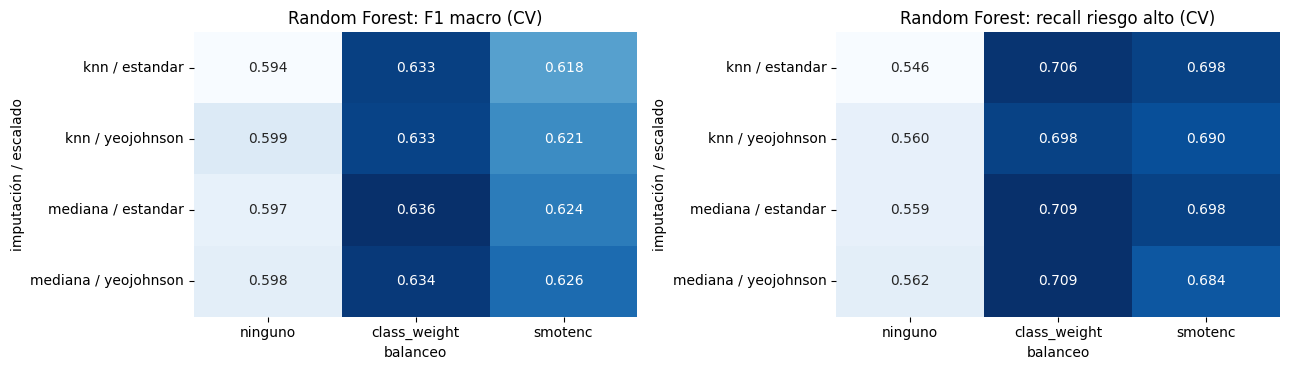

In [5]:
figura_configuraciones(tabla_rf, "Random Forest", "ensembles_random_forest_configuraciones.png")

- El balanceo es lo que más cambia. Sin balancear, el F1 macro se queda en 0,59-0,60 y el recall de riesgo alto en 0,55-0,56, el más bajo de todos los modelos: como Random Forest vota por mayoría, tira hacia riesgo bajo, que es la clase más frecuente. Con `class_weight` sube a 0,63-0,64 de F1 y a 0,70-0,71 de recall.
- La imputación y el escalado casi no cambian nada (menos de una centésima). Es lo esperado, porque a los árboles solo les importa el orden de los valores.
- La mejor configuración es mediana, z-score y `class_weight`, con `max_depth=10`, `min_samples_leaf=5` y `max_features="sqrt"`: F1 macro de 0,636 y recall de riesgo alto de 0,71.
- El F1 en train es 0,98, muy por encima del de validación. En Random Forest es normal, porque cada árbol se ajusta mucho a su muestra y lo que se corrige al hacer la media es la varianza.

## 3. Gradient Boosting

Aquí hay más hiperparámetros y cada modelo tarda más, así que usamos `RandomizedSearchCV` con 25 combinaciones al azar (siempre las mismas por la semilla):

- `n_estimators` (100, 200, 400) y `learning_rate` (0,02, 0,05, 0,1): van juntos, con un `learning_rate` más bajo hacen falta más árboles.
- `max_depth` (2, 3, 4): en boosting los árboles son pequeños.
- `subsample` (0,7 o 1): entrenar cada árbol con una parte de los datos ayuda a no sobreajustar.
- `min_samples_leaf` (1, 10, 30).

Gradient Boosting no tiene `class_weight`, así que en esa configuración se pasan pesos por muestra al entrenar.

In [6]:
gb = GradientBoostingClassifier(random_state=SEED)
tabla_gb, busquedas_gb = ajustar_modelo(
    "gradient_boosting", gb,
    {"n_estimators": [100, 200, 400], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [2, 3, 4],
     "subsample": [0.7, 1.0], "min_samples_leaf": [1, 10, 30]},
    X_train, y_train, n_iter=25)
guardar_tabla(tabla_gb, "ensembles_gradient_boosting")
tabla_gb[COLUMNAS].round(3)

gradient_boosting | mediana-estandar-ninguno         F1 macro 0.635 (±0.031)  recall alto 0.623  [35 s]


gradient_boosting | mediana-estandar-class_weight    F1 macro 0.639 (±0.029)  recall alto 0.690  [39 s]


gradient_boosting | mediana-estandar-smotenc         F1 macro 0.630 (±0.022)  recall alto 0.670  [59 s]


gradient_boosting | mediana-yeojohnson-ninguno       F1 macro 0.635 (±0.023)  recall alto 0.623  [34 s]


gradient_boosting | mediana-yeojohnson-class_weight  F1 macro 0.639 (±0.025)  recall alto 0.684  [39 s]


gradient_boosting | mediana-yeojohnson-smotenc       F1 macro 0.633 (±0.019)  recall alto 0.673  [65 s]


... (3 outputs left out)

gradient_boosting | knn-yeojohnson-ninguno           F1 macro 0.637 (±0.029)  recall alto 0.629  [36 s]


gradient_boosting | knn-yeojohnson-class_weight      F1 macro 0.636 (±0.027)  recall alto 0.704  [36 s]


gradient_boosting | knn-yeojohnson-smotenc           F1 macro 0.626 (±0.020)  recall alto 0.690  [60 s]


,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,f1_macro_std,recall_alto_media,bal_acc_media,accuracy_media,sobreajuste,segundos
0,mediana,estandar,class_weight,"{'subsample': 1.0, 'n_estimators': 400, 'min_s...",0.639,0.029,0.690,0.642,0.662,0.359,38.5
1,mediana,yeojohnson,class_weight,"{'subsample': 1.0, 'n_estimators': 400, 'min_s...",0.639,0.025,0.684,0.642,0.662,0.360,38.5
2,knn,estandar,ninguno,"{'subsample': 1.0, 'n_estimators': 400, 'min_s...",0.639,0.033,0.645,0.637,0.671,0.361,39.8
3,knn,yeojohnson,ninguno,"{'subsample': 0.7, 'n_estimators': 200, 'min_s...",0.637,0.029,0.629,0.632,0.672,0.337,36.3
4,knn,yeojohnson,class_weight,"{'subsample': 0.7, 'n_estimators': 200, 'min_s...",0.636,0.027,0.704,0.643,0.656,0.328,36.4
5,mediana,estandar,ninguno,"{'subsample': 0.7, 'n_estimators': 200, 'min_s...",0.635,0.031,0.623,0.631,0.674,0.352,34.6
6,mediana,yeojohnson,ninguno,"{'subsample': 0.7, 'n_estimators': 200, 'min_s...",0.635,0.023,0.623,0.631,0.673,0.337,34.5
7,knn,estandar,class_weight,"{'subsample': 0.7, 'n_estimators': 200, 'min_s...",0.633,0.032,0.665,0.635,0.659,0.365,36.1
8,mediana,yeojohnson,smotenc,"{'subsample': 0.7, 'n_estimators': 400, 'min_s...",0.633,0.019,0.673,0.633,0.654,0.366,64.6
9,mediana,estandar,smotenc,"{'subsample': 0.7, 'n_estimators': 200, 'min_s...",0.630,0.022,0.670,0.632,0.655,0.367,58.5


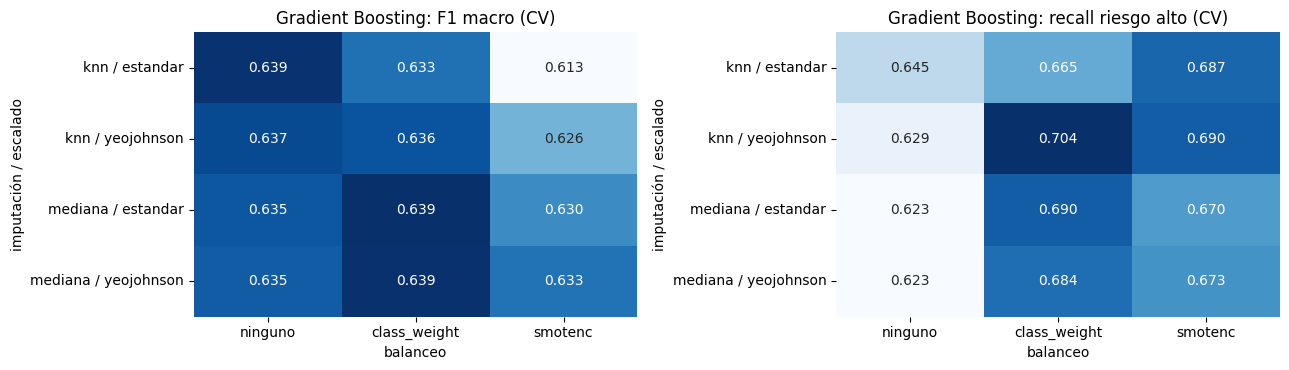

In [7]:
figura_configuraciones(tabla_gb, "Gradient Boosting", "ensembles_gradient_boosting_configuraciones.png")

- Aquí el balanceo cambia poco el F1 macro (0,625-0,637 de media según el balanceo), pero sí el recall de riesgo alto: 0,63 sin balancear y 0,69 con pesos por muestra.
- SMOTE-NC es lo que peor va y además lo más lento: unos 60 s por configuración frente a 35 s, porque entrena con más pacientes.
- La mejor configuración es mediana, z-score y pesos por muestra, con 400 árboles, `learning_rate=0.1`, `max_depth=3`, `min_samples_leaf=30` y `subsample=1`: F1 macro de 0,639 y recall de riesgo alto de 0,69.
- Es el modelo que más sobreajusta: llega a un F1 de 0,999 en train.

### Número de árboles

Con la mejor configuración de Gradient Boosting vemos cómo cambia el F1 macro al ir añadiendo árboles, en train y en validación, con las 5 particiones de siempre. `staged_predict` da la predicción después de cada árbol, así que no hay que entrenar un modelo por cada número de árboles.

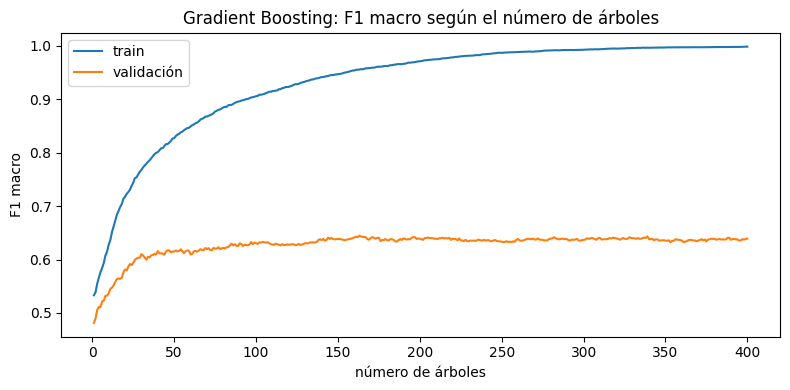

In [8]:
mejor_gb = mejor_configuracion(tabla_gb)
n_arboles = mejor_gb.mejores_parametros["n_estimators"]
curva_train, curva_val = [], []
# los pesos se calculan igual que en la búsqueda: con todo el train y recortados en cada fold
pesos_train = pesos_balanceados(y_train)
for idx_tr, idx_val in particiones_cv().split(X_train, y_train):
    X_tr, y_tr = X_train.iloc[idx_tr], y_train.iloc[idx_tr]
    X_val, y_val = X_train.iloc[idx_val], y_train.iloc[idx_val]
    pipe, extra = pipeline_desde_fila(gb, mejor_gb)
    pesos = {"modelo__sample_weight": pesos_train[idx_tr]} if extra["usar_pesos"] else {}
    pipe.fit(X_tr, y_tr, **pesos)
    previo, modelo = pipe[:-1], pipe[-1]
    curva_train.append([f1_score(y_tr, p, average="macro") for p in modelo.staged_predict(previo.transform(X_tr))])
    curva_val.append([f1_score(y_val, p, average="macro") for p in modelo.staged_predict(previo.transform(X_val))])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, n_arboles + 1), np.mean(curva_train, axis=0), label="train")
ax.plot(range(1, n_arboles + 1), np.mean(curva_val, axis=0), label="validación")
ax.set_xlabel("número de árboles")
ax.set_ylabel("F1 macro")
ax.set_title("Gradient Boosting: F1 macro según el número de árboles")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ensembles_gradient_boosting_arboles.png", dpi=150)
plt.show()

El F1 de train sube hasta casi 1, pero el de validación deja de mejorar hacia los 150 árboles (0,638) y a partir de ahí se queda plano (0,639 con 400). Es decir, los árboles que se añaden después solo sirven para memorizar el train. No empeora la validación, pero se podría usar la mitad de árboles, o parada temprana (`n_iter_no_change`), y tardaría menos.

También vimos que Gradient Boosting es bastante sensible a pequeños cambios: si los pesos por muestra se calculan con el train de cada fold en vez de con todo el train, el F1 macro baja de 0,639 a 0,627. Por eso no nos fiamos de diferencias de una centésima entre modelos y comparamos con la validación cruzada 5x3.

## 4. XGBoost

Con XGBoost también usamos `RandomizedSearchCV` con 25 combinaciones. Además de los hiperparámetros de Gradient Boosting tiene algunos de regularización:

- `colsample_bytree` (0,5, 0,8, 1): parte de las variables que usa cada árbol.
- `min_child_weight` (1 o 5): parecido a `min_samples_leaf`.
- `reg_lambda` (1 o 5): penalización L2 de los pesos de las hojas.

Ponemos `n_jobs=1` dentro de XGBoost porque la búsqueda ya reparte las particiones entre los núcleos. Igual que Gradient Boosting, no tiene `class_weight` y se le pasan pesos por muestra.

In [9]:
xgb = XGBClassifier(random_state=SEED, n_jobs=1, tree_method="hist", eval_metric="mlogloss")
tabla_xgb, busquedas_xgb = ajustar_modelo(
    "xgboost", xgb,
    {"n_estimators": [100, 200, 400], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [2, 3, 4, 6],
     "subsample": [0.7, 1.0], "colsample_bytree": [0.5, 0.8, 1.0], "min_child_weight": [1, 5],
     "reg_lambda": [1, 5]},
    X_train, y_train, n_iter=25)
guardar_tabla(tabla_xgb, "ensembles_xgboost")
tabla_xgb[COLUMNAS].round(3)

xgboost | mediana-estandar-ninguno         F1 macro 0.651 (±0.026)  recall alto 0.681  [8 s]


xgboost | mediana-estandar-class_weight    F1 macro 0.642 (±0.026)  recall alto 0.706  [8 s]


xgboost | mediana-estandar-smotenc         F1 macro 0.640 (±0.027)  recall alto 0.723  [10 s]


xgboost | mediana-yeojohnson-ninguno       F1 macro 0.651 (±0.026)  recall alto 0.681  [8 s]


xgboost | mediana-yeojohnson-class_weight  F1 macro 0.642 (±0.026)  recall alto 0.706  [8 s]


xgboost | mediana-yeojohnson-smotenc       F1 macro 0.639 (±0.028)  recall alto 0.701  [10 s]


... (3 outputs left out)

xgboost | knn-yeojohnson-ninguno           F1 macro 0.649 (±0.024)  recall alto 0.670  [9 s]


xgboost | knn-yeojohnson-class_weight      F1 macro 0.643 (±0.029)  recall alto 0.715  [9 s]


xgboost | knn-yeojohnson-smotenc           F1 macro 0.630 (±0.030)  recall alto 0.698  [11 s]


,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,f1_macro_std,recall_alto_media,bal_acc_media,accuracy_media,sobreajuste,segundos
0,mediana,estandar,ninguno,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimat...",0.651,0.026,0.681,0.651,0.682,0.265,8.1
1,mediana,yeojohnson,ninguno,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimat...",0.651,0.026,0.681,0.651,0.682,0.265,7.9
2,knn,yeojohnson,ninguno,"{'subsample': 0.7, 'reg_lambda': 5, 'n_estimat...",0.649,0.024,0.670,0.647,0.682,0.184,9.2
3,knn,estandar,ninguno,"{'subsample': 0.7, 'reg_lambda': 5, 'n_estimat...",0.645,0.024,0.662,0.643,0.680,0.186,8.6
4,knn,yeojohnson,class_weight,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimat...",0.643,0.029,0.715,0.650,0.662,0.270,9.2
5,mediana,estandar,class_weight,"{'subsample': 0.7, 'reg_lambda': 5, 'n_estimat...",0.642,0.026,0.706,0.649,0.661,0.267,7.6
6,mediana,yeojohnson,class_weight,"{'subsample': 0.7, 'reg_lambda': 5, 'n_estimat...",0.642,0.026,0.706,0.649,0.661,0.267,7.8
7,mediana,estandar,smotenc,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimat...",0.640,0.027,0.723,0.648,0.659,0.238,10.0
8,mediana,yeojohnson,smotenc,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimat...",0.639,0.028,0.701,0.645,0.660,0.237,10.3
9,knn,estandar,class_weight,"{'subsample': 0.7, 'reg_lambda': 5, 'n_estimat...",0.637,0.037,0.770,0.654,0.664,0.266,8.7


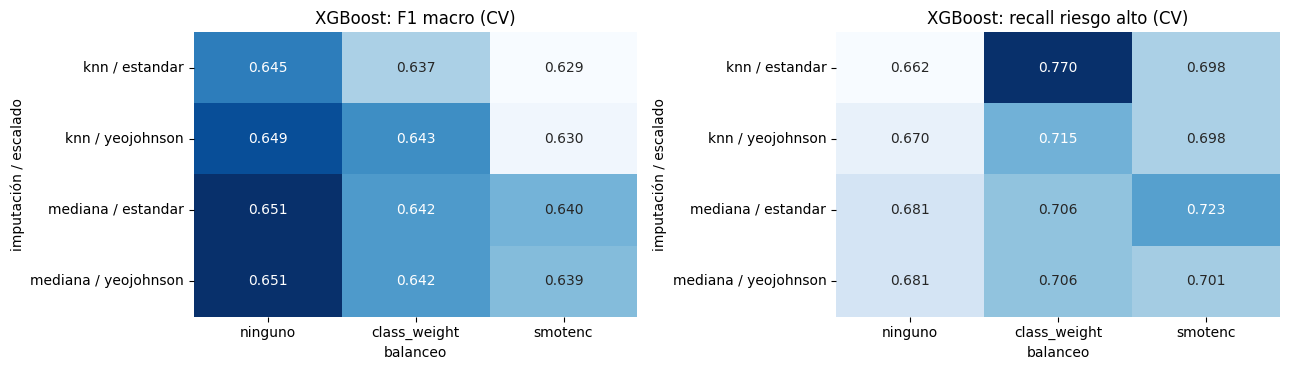

In [10]:
figura_configuraciones(tabla_xgb, "XGBoost", "ensembles_xgboost_configuraciones.png")

- Es el único ensemble en el que gana no balancear: F1 macro de 0,649 de media sin balancear, frente a 0,641 con pesos y 0,635 con SMOTE-NC. A cambio, con pesos el recall de riesgo alto sube de 0,67 a 0,72 de media (0,77 con KNN, z-score y pesos).
- Como en Random Forest, el escalado casi no cambia nada. Con mediana, y sin balancear o con pesos, z-score y Yeo-Johnson dan exactamente lo mismo, porque los árboles solo miran el orden de los valores. Con KNN o SMOTE-NC cambia un poco, porque calculan distancias y esas sí dependen del escalado.
- La mejor configuración es mediana, z-score y sin balanceo, con 400 árboles, `learning_rate=0.1`, `max_depth=2`, `min_child_weight=5`, `subsample=0.7`, `colsample_bytree=0.8` y `reg_lambda=1`: F1 macro de 0,651 y recall de riesgo alto de 0,68.
- Gana con árboles de profundidad 2, muy simples, que solo combinan dos variables cada uno. Sobreajusta menos que los otros dos ensembles (F1 de 0,92 en train).

### Importancia de las variables

Entrenamos la mejor configuración de cada ensemble con todo el train y comparamos qué variables usan más. Es la importancia que se calcula durante el entrenamiento (reducción de impureza en Random Forest y Gradient Boosting, ganancia en XGBoost).

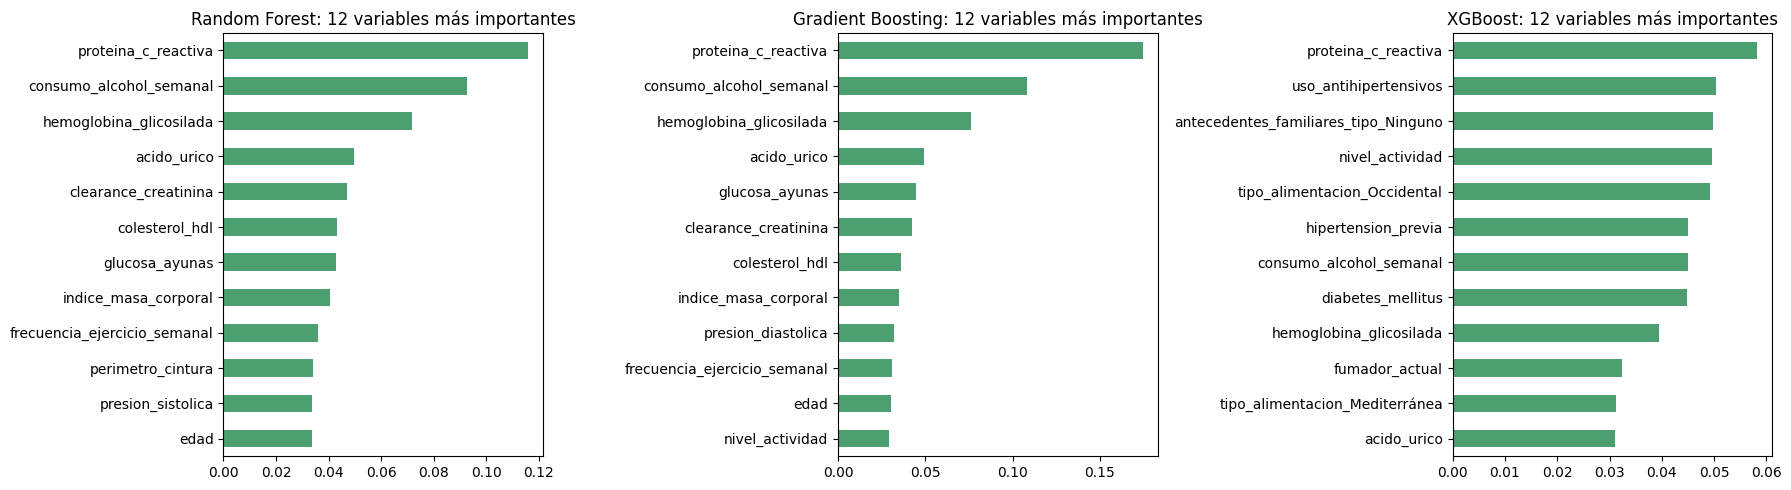

In [11]:
mejor_rf, mejor_xgb = mejor_configuracion(tabla_rf), mejor_configuracion(tabla_xgb)
finales = {"Random Forest": entrenar_final(rf, mejor_rf, X_train, y_train),
           "Gradient Boosting": entrenar_final(gb, mejor_gb, X_train, y_train),
           "XGBoost": entrenar_final(xgb, mejor_xgb, X_train, y_train)}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, pipe) in zip(axes, finales.items()):
    importancias(pipe).head(12).sort_values().plot.barh(ax=ax, color="#4C9F70")
    ax.set_title(f"{nombre}: 12 variables más importantes")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ensembles_importancias.png", dpi=150)
plt.show()

- En Random Forest y Gradient Boosting destacan la proteína C reactiva, el alcohol y la hemoglobina glicosilada, bastante por delante del resto. Después vienen el ácido úrico, el aclaramiento de creatinina, la glucosa y el HDL. Son todas numéricas.
- XGBoost reparte más la importancia y saca arriba las binarias y categóricas: antihipertensivos, no tener antecedentes familiares, nivel de actividad, alimentación occidental, hipertensión previa y diabetes. Son las mismas que más pesaban en la logística.
- Creemos que la diferencia viene de cómo se mide. La importancia por impureza favorece a las variables continuas, porque tienen muchos puntos de corte posibles y se usan en muchas divisiones. XGBoost la mide por la ganancia media de cada división, y ahí una binaria que separa bien cuenta lo mismo aunque se use pocas veces.
- En los tres modelos aparecen arriba la proteína C reactiva, el alcohol y la hemoglobina glicosilada, igual que en el árbol del notebook 04.

## 5. Comparación con los modelos base

Pasamos la validación cruzada 5x3 a la mejor configuración de cada ensemble, con las mismas 15 particiones que usamos con los modelos base, y juntamos los resultados con los del notebook 04.

In [12]:
candidatos = {"random_forest": (rf, mejor_rf), "gradient_boosting": (gb, mejor_gb), "xgboost": (xgb, mejor_xgb)}
cv_ensembles = comparar_modelos(candidatos, X_train, y_train)
guardar_tabla(cv_ensembles, "cv_repetida_ensembles")

cv_base = pd.read_csv(RESULTS_DIR / "cv_repetida_modelos_base.csv")
cv_todos = pd.concat([cv_base, cv_ensembles], ignore_index=True)
resumen = cv_todos.groupby("modelo")[list(METRICAS)].agg(["mean", "std"]).round(3)
resumen.sort_values(("f1_macro", "mean"), ascending=False)

f1_macro        bal_acc        recall_alto         \
                           mean    std    mean    std        mean    std   
modelo                                                                     
xgboost                   0.645  0.027   0.644  0.026       0.679  0.047   
logistica                 0.641  0.029   0.641  0.029       0.670  0.052   
logistica_class_weight    0.640  0.026   0.653  0.029       0.753  0.057   
random_forest             0.630  0.026   0.637  0.026       0.702  0.053   
gradient_boosting         0.625  0.026   0.627  0.025       0.676  0.048   
arbol                     0.528  0.028   0.543  0.027       0.607  0.059   

                       accuracy         
                           mean    std  
modelo                                  
xgboost                   0.676  0.023  
logistica                 0.680  0.025  
logistica_class_weight    0.660  0.021  
random_forest             0.667  0.022  
gradient_boosting         0.648  0.023  
arbol                     0.544  0.025

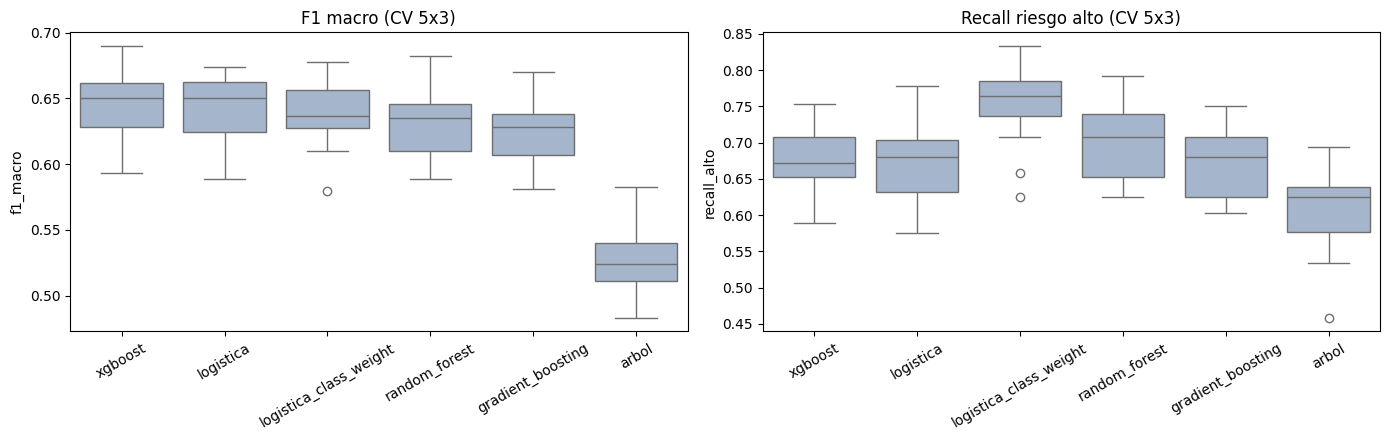

In [13]:
orden = cv_todos.groupby("modelo")["f1_macro"].mean().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m, titulo in [(axes[0], "f1_macro", "F1 macro"), (axes[1], "recall_alto", "Recall riesgo alto")]:
    sns.boxplot(data=cv_todos, x="modelo", y=m, order=orden, ax=ax, color="#9DB4D3")
    ax.set_title(f"{titulo} (CV 5x3)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ensembles_comparacion.png", dpi=150)
plt.show()

- En la validación cruzada 5x3, XGBoost queda primero en F1 macro (0,645), pero casi empatado con la logística (0,641) y con la logística con `class_weight` (0,640). Después van Random Forest (0,630) y Gradient Boosting (0,625). El árbol se queda muy por debajo (0,528).
- Entre los cinco primeros hay unas 2 centésimas, menos que la desviación entre particiones (0,026-0,029), y las cajas se solapan casi del todo. Si alguna diferencia es significativa lo miraremos con el test de Friedman en la comparación final.
- En recall de riesgo alto la mejor sigue siendo la logística con `class_weight` (0,75), seguida de Random Forest (0,70) y XGBoost (0,68).
- En los ensembles el F1 de la 5x3 es algo más bajo que el de la búsqueda (Gradient Boosting de 0,639 a 0,625, Random Forest de 0,636 a 0,630, XGBoost de 0,651 a 0,645), y en la logística casi no cambia (de 0,643 a 0,641). Es normal: al quedarnos con la mejor de muchas combinaciones también elegimos algo de suerte, y cuantos más hiperparámetros se prueban, más optimista sale la búsqueda.

### Sobreajuste

Comparamos el F1 macro en train y en validación de la mejor configuración de cada modelo (sale de la búsqueda de hiperparámetros).

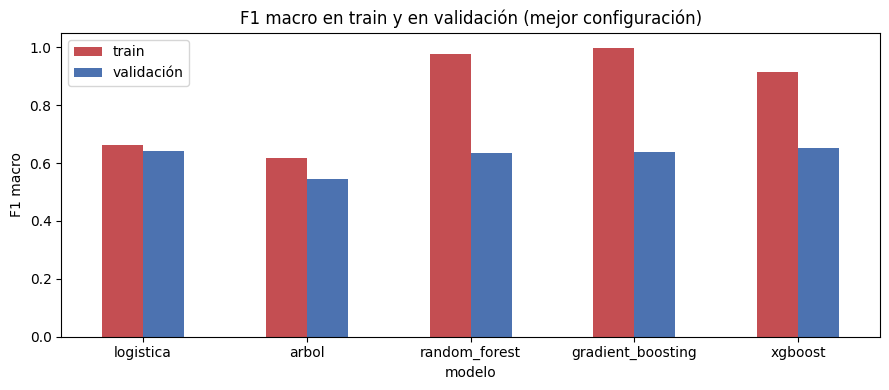

,train,validación
modelo,,
logistica,0.664,0.643
arbol,0.619,0.546
random_forest,0.977,0.636
gradient_boosting,0.999,0.639
xgboost,0.916,0.651


In [14]:
tabla_base = pd.concat([pd.read_csv(RESULTS_DIR / "modelos_base_logistica.csv").head(1),
                        pd.read_csv(RESULTS_DIR / "modelos_base_arbol.csv").head(1)])
filas = pd.concat([tabla_base, tabla_rf.head(1), tabla_gb.head(1), tabla_xgb.head(1)])
sobre = filas.set_index("modelo")[["f1_macro_train", "f1_macro_media"]].rename(
    columns={"f1_macro_train": "train", "f1_macro_media": "validación"})

ax = sobre.plot.bar(figsize=(9, 4), color=["#C44E52", "#4C72B0"], rot=0)
ax.set_ylabel("F1 macro")
ax.set_title("F1 macro en train y en validación (mejor configuración)")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ensembles_sobreajuste.png", dpi=150)
plt.show()
sobre.round(3)

Los tres ensembles casi memorizan el train (F1 de 0,92 a 1), mientras que la logística tiene 0,66 en train y 0,64 en validación. Aun así, en validación los ensembles no son peores que la logística, así que en ellos la diferencia entre train y validación no es mala por sí sola. Lo que sí nos dice es que en este dataset no hay mucha más señal de la que ya capta un modelo lineal: la capacidad extra de los ensembles se va en ajustar ruido del train.

In [15]:
mejores = pd.DataFrame([{"modelo": nombre, **fila[["imputacion", "escalado", "balanceo", "mejores_parametros",
                                                    "f1_macro_media", "recall_alto_media", "bal_acc_media"]]}
                        for nombre, (_, fila) in candidatos.items()])
guardar_tabla(mejores, "mejores_ensembles")
mejores.round(3)

,modelo,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,recall_alto_media,bal_acc_media
0,random_forest,mediana,estandar,class_weight,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.636,0.709,0.643
1,gradient_boosting,mediana,estandar,class_weight,"{'subsample': 1.0, 'n_estimators': 400, 'min_s...",0.639,0.690,0.642
2,xgboost,mediana,estandar,ninguno,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimat...",0.651,0.681,0.651


## 6. Resumen

- Los tres ensembles mejoran mucho al árbol de decisión (de 0,53 a 0,63-0,65 de F1 macro), que es lo que se espera al combinar muchos árboles.
- No mejoran claramente a la logística. XGBoost es el mejor en F1 macro, pero solo por 4 milésimas. Creemos que el riesgo depende de muchas variables con efectos pequeños y casi sumados, y eso un modelo lineal ya lo recoge.
- Random Forest necesita `class_weight`; sin balancear es el modelo con peor recall de riesgo alto. En los modelos de boosting el balanceo cambia poco el F1 macro pero sube el recall de riesgo alto. SMOTE-NC no es la mejor opción en ningún ensemble y es la más lenta.
- Con muchos árboles, Gradient Boosting y Random Forest llegan casi a F1 1 en train sin mejorar la validación. XGBoost, con árboles de profundidad 2 y regularización, es el que menos sobreajusta.

Los mejores ajustes están en `results/mejores_ensembles.csv` y los resultados por partición en `results/cv_repetida_ensembles.csv`, con las mismas particiones que los modelos base. La evaluación en test y los tests estadísticos se harán con todos los modelos juntos.